# Arbeitsblatt 10 – Aufgabe 2.2: Eigene P1-FEM in 2d (numpy, scipy)

**Task:** Solve the boundary value problem (1) from Aufgabe 1.1 with our **own** implementation of first-order FEM in 2d, using the assembling algorithm (Algorithmus 9.1) from the script.

$$
-\Delta u = 1 \text{ in } \Omega=[0,1]^2,\qquad u = 0 \text{ on } \Gamma_1 \text{ (bottom, left)},\qquad \frac{\partial u}{\partial n} = 0 \text{ on } \Gamma_2 \text{ (top, right)}.
$$

From Aufgabe 1.1 we already have the weak form: find $u\in V=\{v\in H^1(\Omega): v=0 \text{ on }\Gamma_1\}$ with

$$ \int_\Omega \nabla u\cdot\nabla v\,dx = \int_\Omega v\,dx \qquad \forall v\in V. $$

**Plan** (each step is one section below):
1. Mesh: points `pts` and triangles `T`
2. Element matrix $A_T$ and element vector $f_T$ via the reference triangle
3. Assembling (Algorithmus 9.1): sum local contributions into the global sparse matrix
4. Dirichlet BC on $\Gamma_1$: solve only on the free DOFs
5. Plot + compare with NGSolve on **the same mesh** (should agree to machine precision)
6. Bonus: Neumann condition $\partial_n u = 1$ (Aufgabe 1.1 part 4) – needs an extra assembling over boundary edges


In [1]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt
import matplotlib.tri as mtri

## 1. Mesh

Like in the script (9.4), we build a structured triangulation: $n\times n$ squares, each cut into two triangles.

* `pts[k] = (x_k, y_k)` – coordinates of global node $k$. Node numbering: $k = i\,(n+1) + j$ with row $i$ ($y$-direction) and column $j$ ($x$-direction).
* `T[e] = [k0, k1, k2]` – the three global node numbers of triangle $e$. **This is the local-to-global map** $T(e, j)$ from Algorithmus 9.1: local vertex $j\in\{0,1,2\}$ of element $e$ ↦ global node `T[e, j]`.

*Important:* the first vertex `T[e,0]` must be the right-angle corner and the order counter-clockwise, then $\det A_T > 0$ (not strictly necessary since we use $|\det A_T|$, but cleaner).

In [2]:
def make_mesh(n):
    xi = np.linspace(0, 1, n + 1)
    X, Y = np.meshgrid(xi, xi)                    # X[i,j] = xi[j], Y[i,j] = xi[i]
    pts = np.column_stack([X.ravel(), Y.ravel()]) # node k = i*(n+1)+j
    T = []
    for i in range(n):                            # row of squares (y)
        for j in range(n):                        # column of squares (x)
            k  = i * (n + 1) + j                  # lower-left corner of the square
            T.append([k,          k + 1,     k + n + 1])   # lower triangle
            T.append([k + n + 2,  k + n + 1, k + 1])       # upper triangle
    return pts, np.array(T)

pts, T = make_mesh(3)
print("pts.shape =", pts.shape, "  T.shape =", T.shape)
print("first triangles:\n", T[:4])

pts.shape = (16, 2)   T.shape = (18, 3)
first triangles:
 [[0 1 4]
 [5 4 1]
 [1 2 5]
 [6 5 2]]


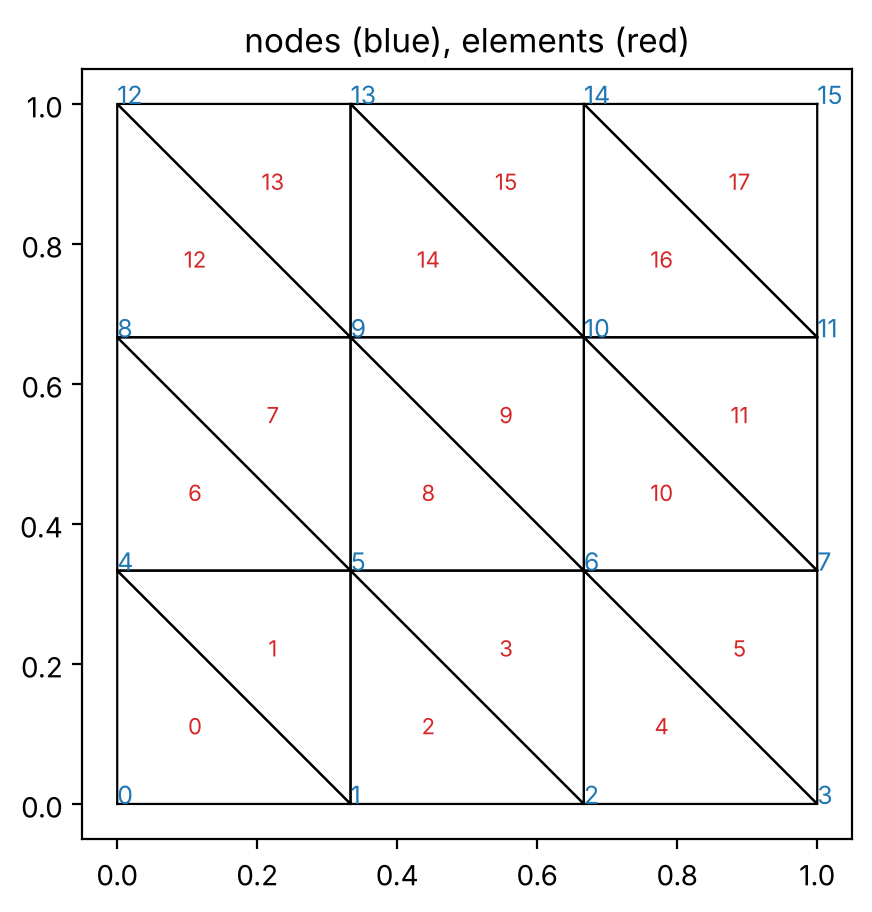

In [3]:
def plot_mesh(pts, T, ax=None):
    ax = ax or plt.gca()
    for e, t in enumerate(T):
        poly = pts[list(t) + [t[0]]]
        ax.plot(poly[:, 0], poly[:, 1], "k-", lw=0.8)
        c = pts[t].mean(axis=0)
        ax.text(*c, str(e), color="tab:red", ha="center", va="center", fontsize=8)
    for k, p in enumerate(pts):
        ax.text(*p, str(k), color="tab:blue", fontsize=9)
    ax.set_aspect("equal"); ax.set_title("nodes (blue), elements (red)")

plt.figure(figsize=(5, 5)); plot_mesh(pts, T); plt.show()

## 2. Element matrix and element vector (reference triangle)

**Reference triangle** $\hat T$ with vertices $(0,0),(1,0),(0,1)$ and the P1 basis

$$\tilde\varphi_0 = 1-\xi-\eta,\quad \tilde\varphi_1 = \xi,\quad \tilde\varphi_2 = \eta, \qquad \nabla\tilde\varphi_0 = \begin{pmatrix}-1\\-1\end{pmatrix},\ \nabla\tilde\varphi_1 = \begin{pmatrix}1\\0\end{pmatrix},\ \nabla\tilde\varphi_2 = \begin{pmatrix}0\\1\end{pmatrix}.$$

**Affine map** to triangle $T_i$ with vertices $p_1,p_2,p_3$:

$$\sigma_i(\xi,\eta) = p_1 + A_i\begin{pmatrix}\xi\\ \eta\end{pmatrix},\qquad A_i = \big(p_2-p_1,\; p_3-p_1\big),\qquad J_i = \det A_i .$$

**Why the reference element?** We compute integrals only once on $\hat T$ and transform. With the chain rule, $\nabla\varphi = A_i^{-T}\nabla\tilde\varphi$, so

$$ (A_T)_{jk} = \int_{T_i}\nabla\varphi_j\cdot\nabla\varphi_k\,dx = \int_{\hat T} \nabla\tilde\varphi_j^T\, \underbrace{A_i^{-1}A_i^{-T}}_{C_i}\, \nabla\tilde\varphi_k\;|J_i|\,d\hat x .$$

For P1 the gradients are **constant**, so the integral is just the integrand times the area $|\hat T| = \tfrac12$:

$$ \boxed{A_T = \tfrac12 |J_i|\; G\, C_i\, G^T},\qquad G = \begin{pmatrix}-1&-1\\1&0\\0&1\end{pmatrix}\ \text{(rows = } \nabla\tilde\varphi_j^T).$$

**Load vector** with $f=1$: $\int_{\hat T}\tilde\varphi_j\,d\hat x = \tfrac16$ for each $j$, so

$$ \boxed{f_T = \int_{T_i} 1\cdot\varphi_j\,dx = |J_i|\,\tfrac16\,(1,1,1)^T = \tfrac{|T_i|}{3}(1,1,1)^T}.$$

(The script computes these integrals with `scipy.integrate.dblquad`. That gives the same numbers but is slow; since everything is constant/linear here, the exact formula is better. We check it against quadrature below.)

In [4]:
G = np.array([[-1., -1.],
              [ 1.,  0.],
              [ 0.,  1.]])                 # gradients of reference basis (rows)

def element_matrices(p):
    # p: (3,2) vertex coordinates of one triangle -> (A_T 3x3, f_T 3)
    A = np.column_stack([p[1] - p[0], p[2] - p[0]])   # A_i = (p2-p1, p3-p1)
    J = np.linalg.det(A)                               # J_i
    Ainv = np.linalg.inv(A)
    Ci = Ainv @ Ainv.T                                 # C_i = A^{-1} A^{-T}
    A_T = 0.5 * abs(J) * G @ Ci @ G.T                  # area of ref. triangle = 1/2
    f_T = abs(J) / 6 * np.ones(3)                      # ∫ φ_j = |J|/6
    return A_T, f_T

A_T, f_T = element_matrices(pts[T[0]])
print("A_T of element 0:\n", A_T)
print("f_T of element 0:", f_T)
print("row sums of A_T:", A_T.sum(axis=1))

A_T of element 0:
 [[ 1.  -0.5 -0.5]
 [-0.5  0.5  0. ]
 [-0.5  0.   0.5]]
f_T of element 0: [0.01851852 0.01851852 0.01851852]
row sums of A_T: [0. 0. 0.]


**Checks:**
* For a right-angle triangle with legs $h$: $A_i = h I$, $J_i = h^2$, $C_i = I/h^2$ ⇒ $A_T$ = exactly the reference matrix from the script (9.2.4): $\begin{pmatrix}1&-\frac12&-\frac12\\-\frac12&\frac12&0\\-\frac12&0&\frac12\end{pmatrix}$, **independent of $h$** (in 2d the factors $h^2$ and $1/h^2$ cancel).
* Row sums are 0: $\sum_k\varphi_k = 1$ ⇒ $\sum_k\nabla\varphi_k = 0$. A constant function has zero "energy".
* Compare with numerical quadrature like in the script:

In [5]:
from scipy.integrate import dblquad
def quadT(f):  # integral over reference triangle: 0<=eta<=1-xi
    return dblquad(lambda eta, xi: f(xi, eta), 0, 1, 0, lambda xi: 1 - xi)[0]

p = pts[T[1]]  # the "upper" triangle (other orientation)
A = np.column_stack([p[1] - p[0], p[2] - p[0]]); J = np.linalg.det(A)
Ai = np.linalg.inv(A); Ci = Ai @ Ai.T
A_quad = np.array([[quadT(lambda x, y: G[j] @ Ci @ G[k] * abs(J)) for k in range(3)] for j in range(3)])
print("max |A_T(formula) - A_T(quad)| =", np.abs(element_matrices(p)[0] - A_quad).max())

max |A_T(formula) - A_T(quad)| = 1.1102230246251565e-16


## 3. Assembling – Algorithmus 9.1

Algorithmus 9.1 in the script (1d version):

```
for i in range(n):                 # over elements
    compute local matrix A_e
    for j in range(p+1):           # local index
        for k in range(p+1):       # local index
            A[T(i,j), T(i,k)] += (A_e)[j,k]
```

In 2d it is **exactly the same** – only the element is a triangle (3 local DOFs) and $A_e$ comes from section 2. Same for the right-hand side: `f[T(i,j)] += (f_e)[j]`.

**Why assembling?** We never construct the global hat functions. Each global entry $A_{kl} = \int_\Omega \nabla\varphi_k\cdot\nabla\varphi_l$ is a sum of integrals over the triangles where both $\varphi_k$ and $\varphi_l$ are non-zero, and these are exactly the local contributions.

**Why sparse?** Node $k$ only "sees" its neighbours, so each row has ≤ 7 non-zeros. A dense $N\times N$ matrix would waste memory ($N=10^4$ ⇒ $10^8$ entries). We use `scipy.sparse.lil_matrix` because it allows cheap `+=` of single entries, then convert to CSR (fast for solving).

In [6]:
def assemble(pts, T):
    N = len(pts)
    A = sp.lil_matrix((N, N))
    f = np.zeros(N)
    for i in range(len(T)):                     # loop over elements
        A_e, f_e = element_matrices(pts[T[i]])
        for j in range(3):                      # local index j
            f[T[i, j]] += f_e[j]
            for k in range(3):                  # local index k
                A[T[i, j], T[i, k]] += A_e[j, k]
    return A.tocsr(), f

A, f = assemble(pts, T)
np.set_printoptions(precision=2, suppress=True, linewidth=150)
print(A.toarray())
print("f =", f)
print("sum(f) =", f.sum(), " (= ∫_Ω 1 dx = area = 1)")

[[ 1.  -0.5  0.   0.  -0.5  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0. ]
 [-0.5  2.  -0.5  0.   0.  -1.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0. ]
 [ 0.  -0.5  2.  -0.5  0.   0.  -1.   0.   0.   0.   0.   0.   0.   0.   0.   0. ]
 [ 0.   0.  -0.5  1.   0.   0.   0.  -0.5  0.   0.   0.   0.   0.   0.   0.   0. ]
 [-0.5  0.   0.   0.   2.  -1.   0.   0.  -0.5  0.   0.   0.   0.   0.   0.   0. ]
 [ 0.  -1.   0.   0.  -1.   4.  -1.   0.   0.  -1.   0.   0.   0.   0.   0.   0. ]
 [ 0.   0.  -1.   0.   0.  -1.   4.  -1.   0.   0.  -1.   0.   0.   0.   0.   0. ]
 [ 0.   0.   0.  -0.5  0.   0.  -1.   2.   0.   0.   0.  -0.5  0.   0.   0.   0. ]
 [ 0.   0.   0.   0.  -0.5  0.   0.   0.   2.  -1.   0.   0.  -0.5  0.   0.   0. ]
 [ 0.   0.   0.   0.   0.  -1.   0.   0.  -1.   4.  -1.   0.   0.  -1.   0.   0. ]
 [ 0.   0.   0.   0.   0.   0.  -1.   0.   0.  -1.   4.  -1.   0.   0.  -1.   0. ]
 [ 0.   0.   0.   0.   0.   0.   0.  -0.5  0.   0.  -1.   2.   0.   0.   0.  -0.5]
 [ 0

**What to look at:**
* $A$ is **symmetric** and has **zero row sums** (before BCs) – same reason as for $A_T$.
* An interior node gets $4$ on the diagonal and $-1$ for its 4 axis neighbours, 0 for the diagonal neighbours: the classical 5-point finite-difference stencil. (FD writes $\frac1{h^2}(4u_k-\sum u_\text{nb}) = 1$, FEM gives $4u_k-\sum u_\text{nb} = h^2$ for interior nodes, the same equation multiplied by $h^2$.)
* $\sum f = |\Omega| = 1$ because $\sum_k \varphi_k = 1$.

## 4. Dirichlet boundary condition on $\Gamma_1$ and solve

$u=0$ on $\Gamma_1$ is an **essential** BC: it goes into the space $V$. Discretely: the DOFs on $\Gamma_1$ (nodes with $x=0$ or $y=0$) are fixed to 0 and are **not** unknowns. So we

1. collect the **free DOFs** = all nodes not on $\Gamma_1$ (this includes the nodes on $\Gamma_2$! there $u$ is unknown),
2. solve the reduced system $A[\text{free},\text{free}]\;u[\text{free}] = f[\text{free}]$,
3. keep $u=0$ on $\Gamma_1$.

That's the same as `a.mat.Inverse(V.FreeDofs())` in NGSolve. (If the Dirichlet value were $\neq 0$ we would need to move $A[\text{free},\text{dir}]\,u_\text{dir}$ to the right-hand side.)

The Neumann condition $\partial_n u = 0$ on $\Gamma_2$ needs **no code at all**: its boundary integral is 0 (see 1.1).

In [7]:
def solve_fem(n, neumann_value=0.0):
    pts, T = make_mesh(n)
    A, f = assemble(pts, T)
    if neumann_value != 0.0:                      # bonus (section 6)
        f += assemble_neumann(pts, n, neumann_value)
    tol = 1e-12
    dirichlet = (pts[:, 0] < tol) | (pts[:, 1] < tol)   # Γ1: x=0 or y=0
    free = np.where(~dirichlet)[0]
    u = np.zeros(len(pts))                         # u = 0 on Γ1
    u[free] = spla.spsolve(A[free][:, free].tocsc(), f[free])
    return pts, T, A, u

n = 20
pts, T, A, u = solve_fem(n)
print(f"N = {len(pts)} nodes, {len(T)} triangles, nnz(A) = {A.nnz}")
print("u(1,1) =", u[-1])

N = 441 nodes, 800 triangles, nnz(A) = 2121
u(1,1) = 0.29391862084980314


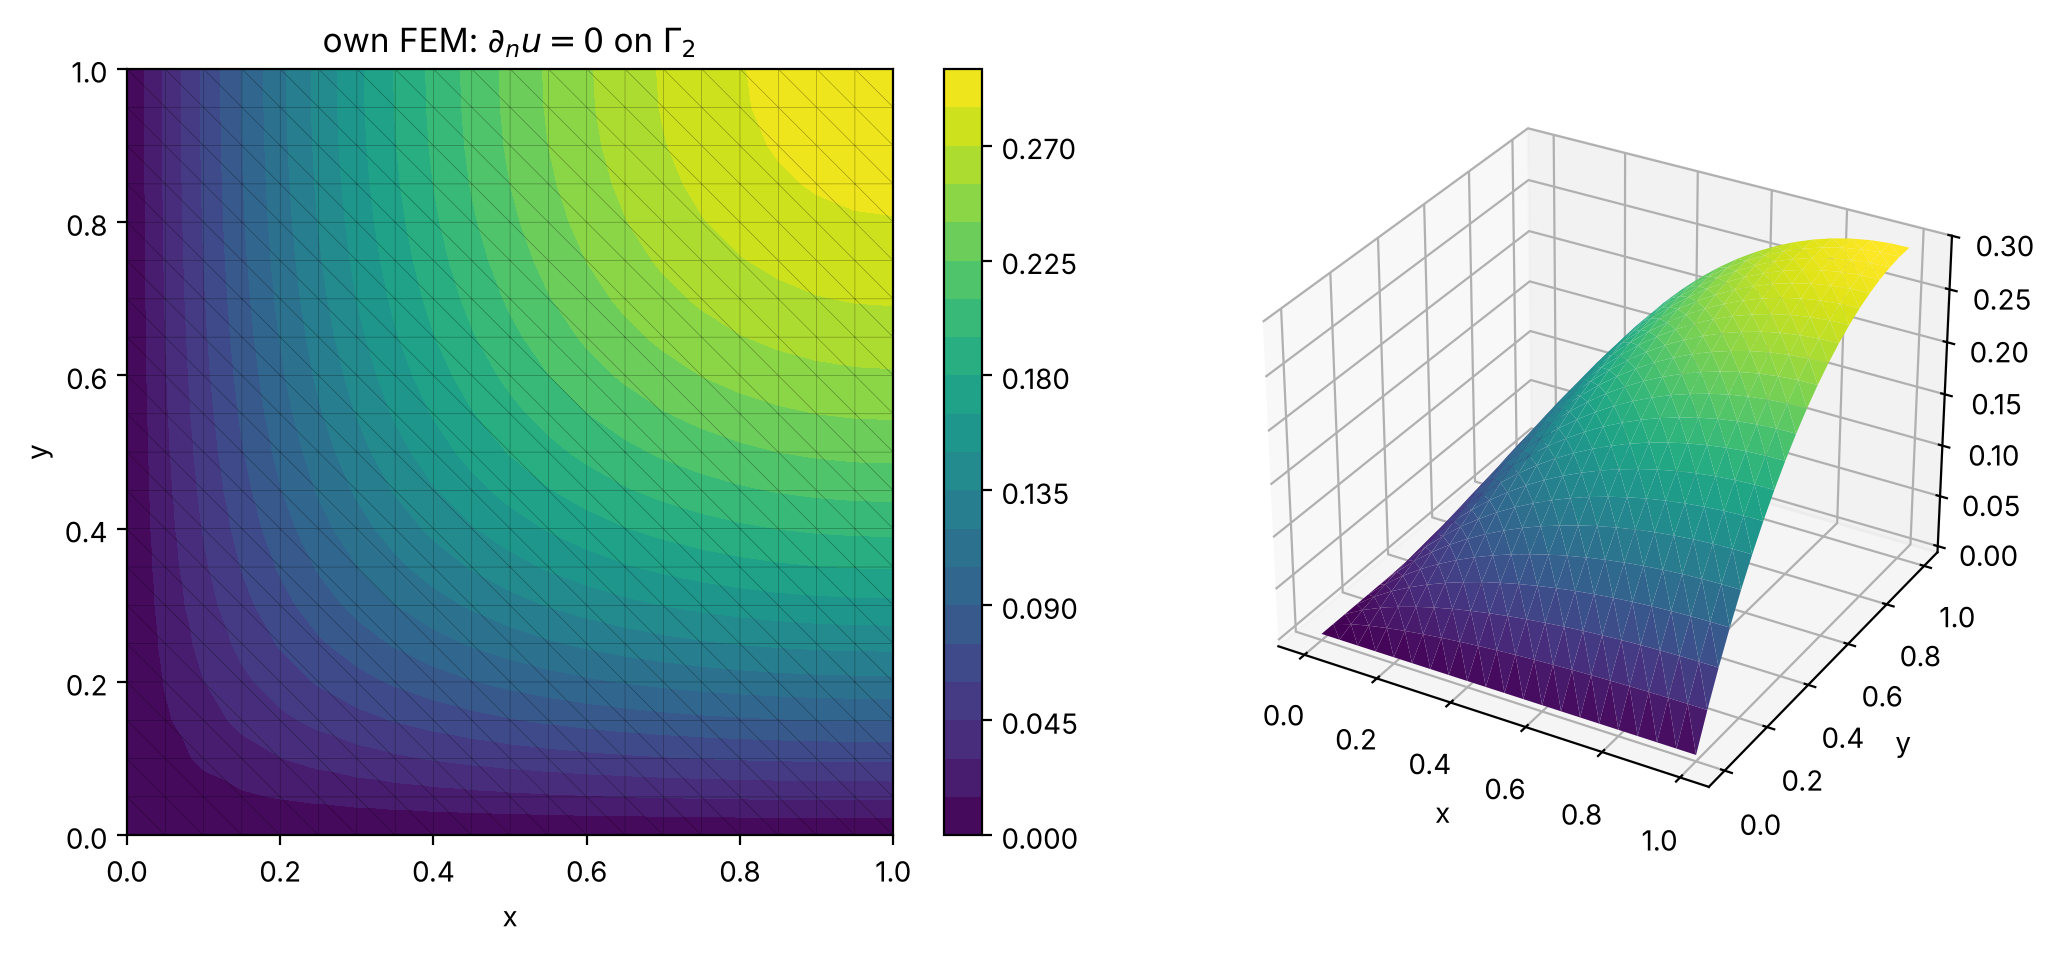

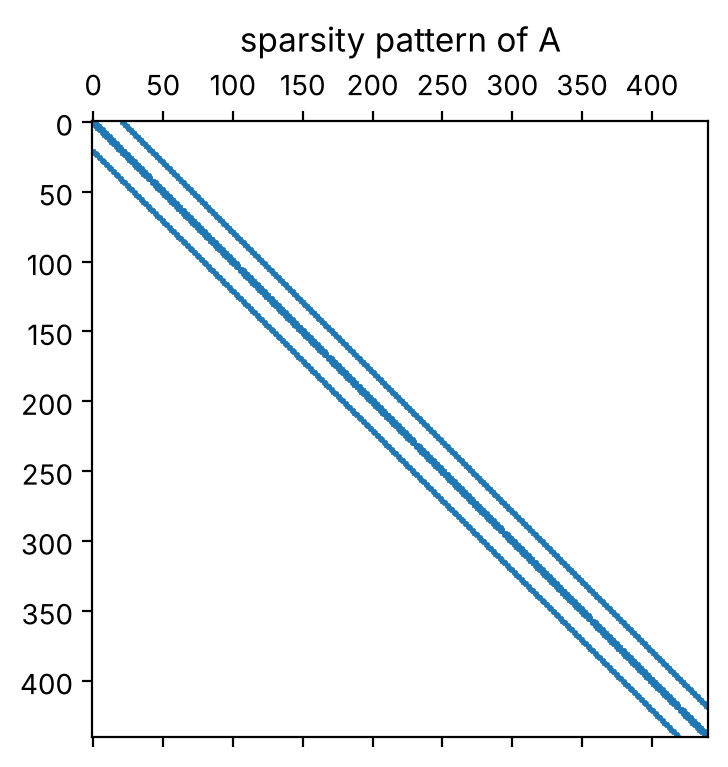

In [8]:
def plot_solution(pts, T, u, title):
    tri = mtri.Triangulation(pts[:, 0], pts[:, 1], T)
    fig = plt.figure(figsize=(11, 4.5))
    ax1 = fig.add_subplot(1, 2, 1)
    cf = ax1.tricontourf(tri, u, levels=20, cmap="viridis")
    ax1.triplot(tri, lw=0.2, color="k", alpha=0.4)
    fig.colorbar(cf, ax=ax1); ax1.set_aspect("equal"); ax1.set_title(title)
    ax1.set_xlabel("x"); ax1.set_ylabel("y")
    ax2 = fig.add_subplot(1, 2, 2, projection="3d")
    ax2.plot_trisurf(tri, u, cmap="viridis"); ax2.set_xlabel("x"); ax2.set_ylabel("y")
    plt.tight_layout(); plt.show()

plot_solution(pts, T, u, r"own FEM: $\partial_n u = 0$ on $\Gamma_2$")

plt.figure(figsize=(4, 4)); plt.spy(A, markersize=1); plt.title("sparsity pattern of A"); plt.show()

## 5. Comparison with NGSolve on the identical mesh

To check our code, we give NGSolve **exactly our mesh** (same points, same triangles) and solve the same weak form. Then both are the same discrete problem, and the difference must be at the level of rounding errors ($\sim10^{-14}$), not just "small".

We build the netgen mesh by hand: points, triangles (`Element2D`) and boundary edges (`Element1D`) with a boundary name, so we can again write `dirichlet="gamma1"`.

In [9]:
from ngsolve import *
from netgen.meshing import Mesh as NGMesh, MeshPoint, Pnt, Element2D, Element1D, FaceDescriptor

def to_ngsolve(pts, T, n):
    m = NGMesh(dim=2)
    pids = [m.Add(MeshPoint(Pnt(x, y, 0))) for x, y in pts]
    m.Add(FaceDescriptor(surfnr=1, domin=1, bc=1))
    for t in T:
        m.Add(Element2D(1, [pids[k] for k in t]))
    idx = lambda i, j: i * (n + 1) + j
    for k in range(n):        # boundary edges: bottom, left -> 1 ; top, right -> 2
        m.Add(Element1D([pids[idx(0, k)],     pids[idx(0, k+1)]],   index=1))
        m.Add(Element1D([pids[idx(k, 0)],     pids[idx(k+1, 0)]],   index=1))
        m.Add(Element1D([pids[idx(n, k)],     pids[idx(n, k+1)]],   index=2))
        m.Add(Element1D([pids[idx(k, n)],     pids[idx(k+1, n)]],   index=2))
    m.SetBCName(0, "gamma1"); m.SetBCName(1, "gamma2")
    return Mesh(m)

def solve_ngsolve(pts, T, n, neumann_value=0.0):
    mesh = to_ngsolve(pts, T, n)
    V = H1(mesh, order=1, dirichlet="gamma1")
    uu, vv = V.TnT()
    a = BilinearForm(grad(uu) * grad(vv) * dx).Assemble()
    l = LinearForm(V); l += 1 * vv * dx
    if neumann_value != 0.0:
        l += neumann_value * vv * ds("gamma2")
    l.Assemble()
    gfu = GridFunction(V); gfu.vec.data = a.mat.Inverse(V.FreeDofs()) * l.vec
    return np.array([gfu(mesh(x, y)) for x, y in pts])

u_ng = solve_ngsolve(pts, T, n)
print("max |u_own - u_ngsolve| =", np.abs(u - u_ng).max())
print("u(1,1): own =", u[-1], "  NGSolve =", u_ng[-1])

max |u_own - u_ngsolve| = 4.440892098500626e-15
u(1,1): own = 0.29391862084980314   NGSolve = 0.2939186208498075


**Convergence check:** refining the mesh, $u(1,1)$ should converge to the same value as in Aufgabe 1.1 ($\approx 0.2947$, from the mirror trick).

In [10]:
for n_ in [5, 10, 20, 40, 80]:
    p_, T_, A_, u_ = solve_fem(n_)
    print(f"n = {n_:3d}   h = {1/n_:.4f}   u(1,1) = {u_[-1]:.6f}")

n =   5   h = 0.2000   u(1,1) = 0.285395
n =  10   h = 0.1000   u(1,1) = 0.291988
n =  20   h = 0.0500   u(1,1) = 0.293919
n =  40   h = 0.0250   u(1,1) = 0.294471


n =  80   h = 0.0125   u(1,1) = 0.294626


## 6. Bonus: Neumann condition $\partial_n u = 1$ on $\Gamma_2$ (Aufgabe 1.1, part 4)

From 1.1 part 3 the right-hand side gets the boundary term $\int_{\Gamma_2} 1\cdot v\,ds$. This is an integral over **edges**, so we do the same assembling again, now with **1d elements** (the boundary edges of $\Gamma_2$) – this is literally Algorithmus 9.1 from the 1d chapter:

* Reference interval $[0,1]$, basis $\tilde\varphi_0 = 1-t$, $\tilde\varphi_1 = t$, each with $\int_0^1\tilde\varphi_j\,dt = \tfrac12$.
* An edge of length $h_e$: $\int_e g\,\varphi_j\,ds = g\,h_e\cdot\tfrac12$ ⇒ local vector $g\frac{h_e}{2}(1,1)^T$.
* Add to the two global nodes of the edge.

The matrix does **not** change.

max |u_own - u_ngsolve| = 1.84297022087776e-14
u(1,1) = 1.6436443653925514


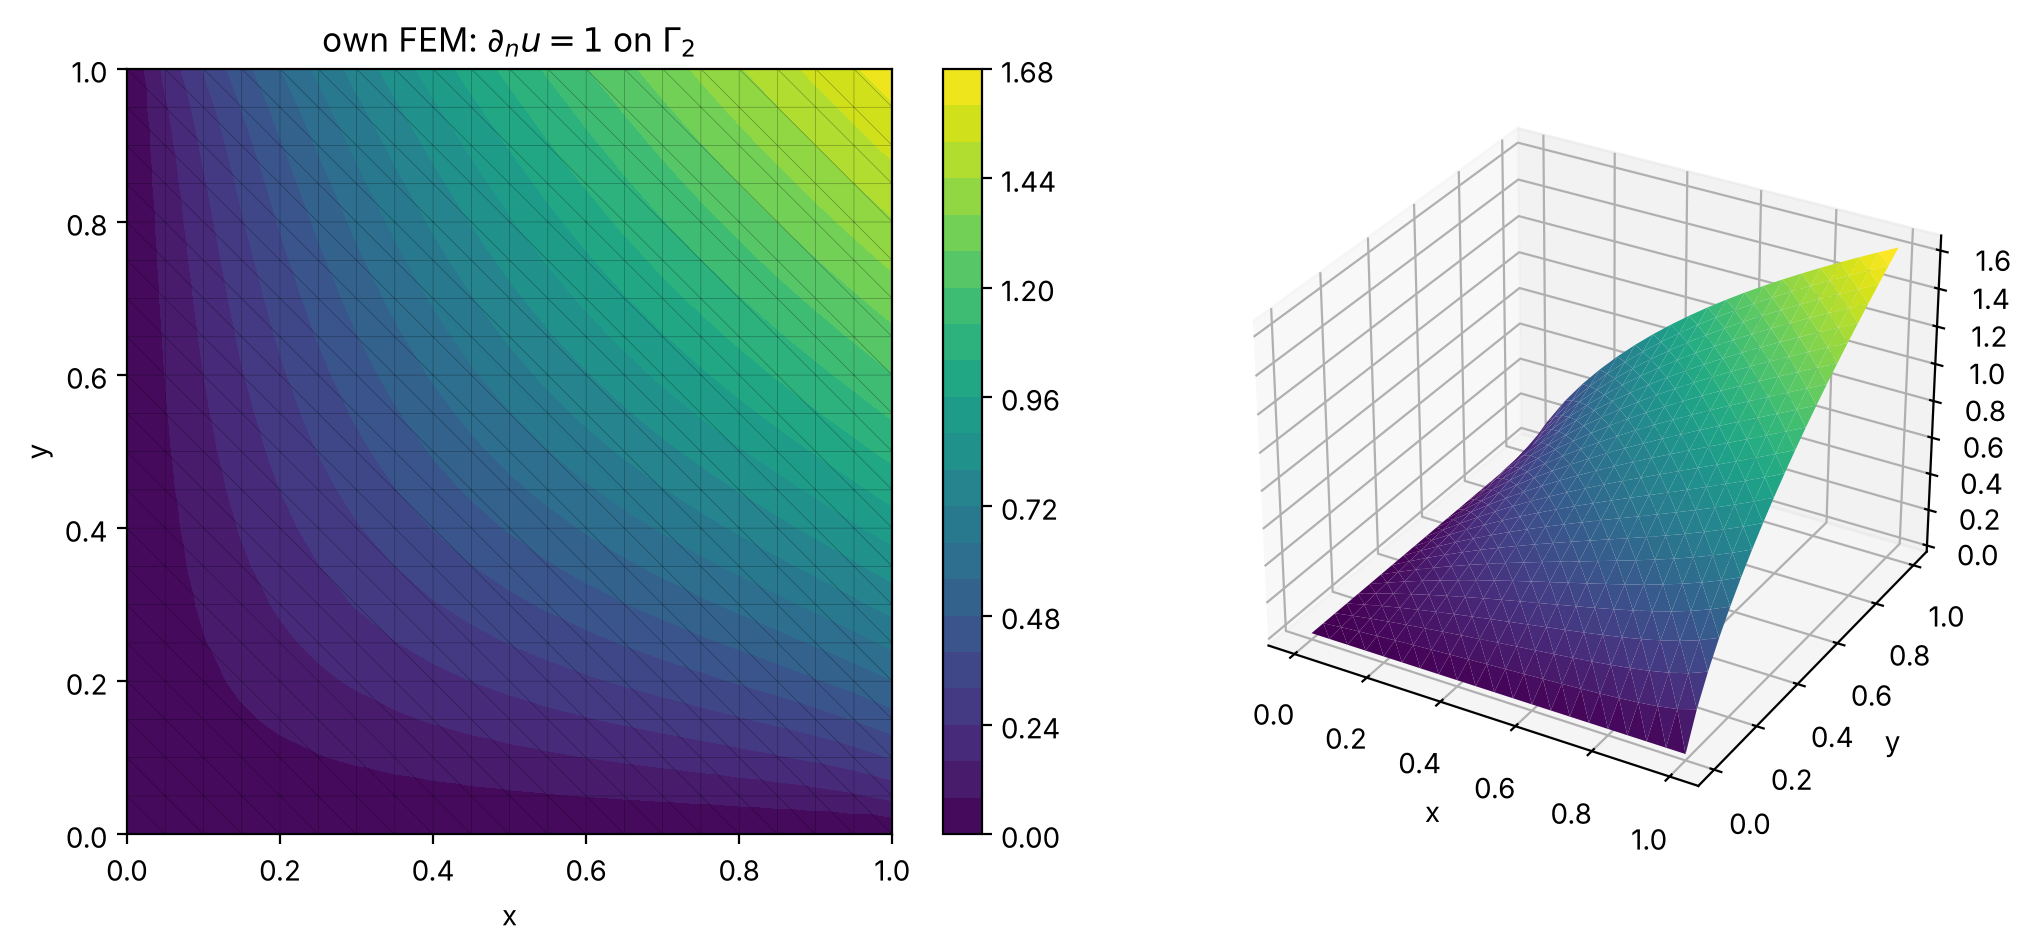

In [11]:
def assemble_neumann(pts, n, g):
    idx = lambda i, j: i * (n + 1) + j
    edges = [(idx(n, k), idx(n, k + 1)) for k in range(n)]    # top edge   y = 1
    edges += [(idx(k, n), idx(k + 1, n)) for k in range(n)]   # right edge x = 1
    fN = np.zeros(len(pts))
    for e in edges:                                           # loop over boundary elements
        h_e = np.linalg.norm(pts[e[1]] - pts[e[0]])
        f_e = g * h_e / 2 * np.ones(2)                        # local vector
        for j in range(2):
            fN[e[j]] += f_e[j]                                # local -> global
    return fN

n = 20
pts, T, A, u1 = solve_fem(n, neumann_value=1.0)
u1_ng = solve_ngsolve(pts, T, n, neumann_value=1.0)
print("max |u_own - u_ngsolve| =", np.abs(u1 - u1_ng).max())
print("u(1,1) =", u1[-1])
plot_solution(pts, T, u1, r"own FEM: $\partial_n u = 1$ on $\Gamma_2$")

## Summary – what goes on paper

1. **Mesh:** points $p_k$, triangles $T_i$, local-to-global map $T(i,j)$.
2. **Affine map:** $\sigma_i(\xi,\eta) = p_{i,1} + A_i(\xi,\eta)^T$, $A_i = (p_{i,2}-p_{i,1},\,p_{i,3}-p_{i,1})$, $J_i=\det A_i$, $C_i = A_i^{-1}A_i^{-T}$.
3. **Element matrix (P1):** $(A_{T_i})_{jk} = \int_{\hat T}\nabla\tilde\varphi_j^T C_i\nabla\tilde\varphi_k\,|J_i|\,d\hat x = \tfrac12|J_i|\,\nabla\tilde\varphi_j^T C_i\nabla\tilde\varphi_k$.
4. **Element vector ($f=1$):** $(f_{T_i})_j = \tfrac{|J_i|}{6}$.
5. **Assembling (Alg. 9.1):** for each $T_i$: $A_{T(i,j),T(i,k)} \mathrel{+}= (A_{T_i})_{jk}$, $f_{T(i,j)} \mathrel{+}= (f_{T_i})_j$, $j,k\in\{0,1,2\}$.
6. **Dirichlet ($\Gamma_1$):** remove those DOFs, solve $A_{FF}u_F = f_F$, set $u=0$ on $\Gamma_1$.
7. **Neumann ($\Gamma_2$):** $\partial_n u=0$ → nothing to do. $\partial_n u = 1$ → per boundary edge $e$: $f \mathrel{+}= \tfrac{h_e}{2}(1,1)^T$.
8. **Result:** identical to NGSolve on the same mesh (difference ≈ $10^{-15}$), $u(1,1)\to\approx0.295$ ($\partial_n u=0$).
